In [23]:
import os
import sys
import time

import joblib
import pandas as pd
import numpy as np
from sklearn.decomposition import PCA
from sklearn.neighbors import LocalOutlierFactor

sys.path.insert(0, '../../..')
from utils.helper_functions import normalize_series
from utils.plotting import plot_movement_data
from utils.constants import Configs

TARGET_MOVEMENT = 'Move'

In [24]:
# Load the processed data from the csv
cache_path = Configs.ICATER_ALL_SENSORS_FILTERED_DATA_DIR
if not os.path.exists(cache_path):
    raise FileNotFoundError(f"Processed data not found at {cache_path}. Please run the data processing notebook first.")

df = pd.read_csv(cache_path)

In [25]:
# Load the known outliers from the csv
outliers_csv = pd.read_csv(Configs.ICATER_OUTLIER_FILES).drop_duplicates(subset=['sub', 'repID'])
total_known_outliers = len(outliers_csv)

print(f"Total known outliers: {total_known_outliers}")
outliers_csv.head()

Total known outliers: 14


,sub,repID
0,2,2
1,4,1
2,5,2
3,5,5
4,7,1


In [26]:
group_array = ['xs', 'ys', 'zs', 'xe', 'ye', 'ze', 'xw', 'yw', 'zw']
sample_size = None

X_movement = normalize_series(
        df_input=df,
        movLabel_filter=TARGET_MOVEMENT,
        useScaler=False,
        group_array=group_array,
        sample_size=sample_size
)  # shape (n_samples, T, n_features)

Processing time series:   0%|          | 0/95 [00:00<?, ?it/s]

Processing time series: 100%|██████████| 95/95 [00:00<00:00, 3642.12it/s]

Shape of first series: (72, 9)
Shape of formatted series: (95, 196, 9)


## PCA

In [27]:
# Preparar Dados para o PCA + LOF

# 1. Extrair TODAS as coordenadas (Ombro, Cotovelo, Mão)
# Aqui usamos o array inteiro (n_samples, n_timepoints, 9)
X_all = X_movement.copy() 
n_samples, n_timepoints, n_dims = X_all.shape

# 2. LIMPEZA DE NaNs (Forward Fill - Obrigatório para PCA)
# Vamos percorrer cada amostra e cada uma das 9 dimensões
for i in range(n_samples):
    for j in range(n_dims):
        # Usamos o Pandas temporariamente para preencher os buracos do tempo
        s = pd.Series(X_all[i, :, j])
        X_all[i, :, j] = s.ffill().bfill().values

# 3. O Truque da Concatenação (Esmagar de 3D para 2D)
# Passamos de (380, 241, 9) para uma matriz plana (380 repetições, ~2169 features)
X_flat = np.transpose(X_all, (0, 2, 1)).reshape(n_samples, n_timepoints * n_dims)

In [28]:
df_filtered = df[df['movLabel'] == TARGET_MOVEMENT].copy()
results_temp_base = df_filtered[['sub', 'repID', 'movID']].drop_duplicates().sort_values(by=['sub', 'repID', 'movID']).reset_index(drop=True)

total_trials = len(results_temp_base)
known_outlier_rate = total_known_outliers / total_trials
percentagem_conhecida = known_outlier_rate * 100

# PCA grid search parameters
min_n_components = 3
max_n_components = 20

# LOF grid search parameters
min_contam = 0.01
max_contam = known_outlier_rate + 0.10         
contamination_range = [round(c, 3) for c in np.linspace(min_contam, max_contam, 15)]
n_neighbors_options = [3, 5, 7, 10, 15, 20]

results_log = []

for n_comp in range(min_n_components, max_n_components + 1):
    pca_start_time = time.perf_counter()
    pca = PCA(n_components=n_comp)
    pca_scores_reduced = pca.fit_transform(X_flat)
    pca_end_time = time.perf_counter()

    for n_neigh in n_neighbors_options:
        for contam in contamination_range:
            lof_start_time = time.perf_counter()

            # TREINO DO LOF
            model = LocalOutlierFactor(n_neighbors=n_neigh, contamination=contam, metric='minkowski')
            labels = model.fit_predict(pca_scores_reduced)
            lof_end_time = time.perf_counter()
        
            # --- CÁLCULO DE MÉTRICAS ---
            results_temp = results_temp_base.copy()
            results_temp['label'] = labels
            
            real_outliers_info = results_temp[results_temp['label'] == -1]
            identified_unique = real_outliers_info.drop_duplicates(subset=['sub', 'repID'])
            
            matched_outliers = pd.merge(identified_unique, outliers_csv, on=['sub', 'repID'], how='inner')
            missing_outliers = pd.merge(outliers_csv, identified_unique, on=['sub', 'repID'], how='left', indicator=True)
            missing_outliers = missing_outliers[missing_outliers['_merge'] == 'left_only']
            
            TP = len(matched_outliers)
            FP = len(identified_unique) - TP
            FN = len(missing_outliers)
            
            if (TP + FP) > 0:
                precision = (TP / (TP + FP)) * 100
                recall = (TP / total_known_outliers) * 100
                f1_score = (2 * precision * recall) / (precision + recall) if (precision + recall) > 0 else 0
                f2_score = (5 * precision * recall) / (4 * precision + recall) if (precision + recall) > 0 else 0
            else:
                precision, recall, f1_score, f2_score = 0.0, 0.0, 0.0, 0.0
                
            percentagem_lixo = (len(real_outliers_info) / total_trials) * 100
                
            results_log.append({
                'n_neighbors': n_neigh,
                'n_components': n_comp,
                'contamination': contam,
                'total_time': (pca_end_time - pca_start_time) + (lof_end_time - lof_start_time),
                'Recall': recall,
                'Precision': precision,
                'F1-Score': f1_score,
                'F2-Score': f2_score,
                'TP': TP,
                'FP': FP,
                'FN': FN,
                'Percentagem Lixo': percentagem_lixo
            })

In [29]:
# --- SELEÇÃO DO MELHOR MODELO ---
results_df = pd.DataFrame(results_log)
limite_lixo = percentagem_conhecida + 5.0 
acceptable_models = results_df[results_df['Percentagem Lixo'] <= limite_lixo]

if acceptable_models.empty:
    acceptable_models = results_df

best_results = acceptable_models.sort_values(by=['Recall', 'F2-Score'], ascending=False)
best_params = best_results.iloc[0]

print(f"\n🏆 VENCEDOR (LOF + PCA):")
print(f"N Components (PCA): {best_params['n_components']}")
print(f"N Neighbors: {best_params['n_neighbors']} | Contamination: {best_params['contamination']}")
print(f"Precision: {best_params['Precision']:.2f}%")
print(f"Recall: {best_params['Recall']:.2f}%")
print(f"F1-Score: {best_params['F1-Score']:.2f}%")
print(f"F2-Score: {best_params['F2-Score']:.2f}%")
print(f"Total Time: {best_params['total_time']:.4f} segundos")


🏆 VENCEDOR (LOF + PCA):
N Components (PCA): 12.0
N Neighbors: 5.0 | Contamination: 0.129
Precision: 69.23%
Recall: 64.29%
F1-Score: 66.67%
F2-Score: 65.22%
Total Time: 0.1064 segundos


In [30]:
print("\n--- A EXTRAIR AS TRAJETÓRIAS ANÓMALAS ORIGINAIS ---")

# 1. Recuperar os parâmetros exatos do modelo vencedor
best_n_comp = int(best_params['n_components'])
best_n_neigh = int(best_params['n_neighbors'])
best_contam = best_params['contamination']

# 2. Re-treinar a pipeline final apenas com os parâmetros vencedores
pca_final = PCA(n_components=best_n_comp)
pca_scores_final = pca_final.fit_transform(X_flat)

model_final = LocalOutlierFactor(n_neighbors=best_n_neigh, contamination=best_contam, metric='minkowski')
final_labels = model_final.fit_predict(pca_scores_final)

# 3. Descobrir QUAIS são os índices dos outliers (onde a label é -1)
outlier_indices = np.where(final_labels == -1)[0]
n_outliers = len(outlier_indices)

# 4. Cortar o array original (X_movement) usando esses índices!
# O X_movement tem os dados puros (n_samples, n_timepoints, 9)
X_movement_clean = np.delete(X_movement, outlier_indices, axis=0)
X_movement_outliers = X_movement[outlier_indices]

print(f"Total de Repetições Originais: {len(X_movement)}")
print(f"Outliers Detetados: {n_outliers}")
print(f"Retenção: {(len(X_movement) - n_outliers) / len(X_movement) * 100:.2f}%")
print(f"Percentagem de lixo: {n_outliers / len(X_movement) * 100:.2f}%")


--- A EXTRAIR AS TRAJETÓRIAS ANÓMALAS ORIGINAIS ---
Total de Repetições Originais: 95
Outliers Detetados: 13
Retenção: 86.32%
Percentagem de lixo: 13.68%


A desenhar trajetórias do Ombro...


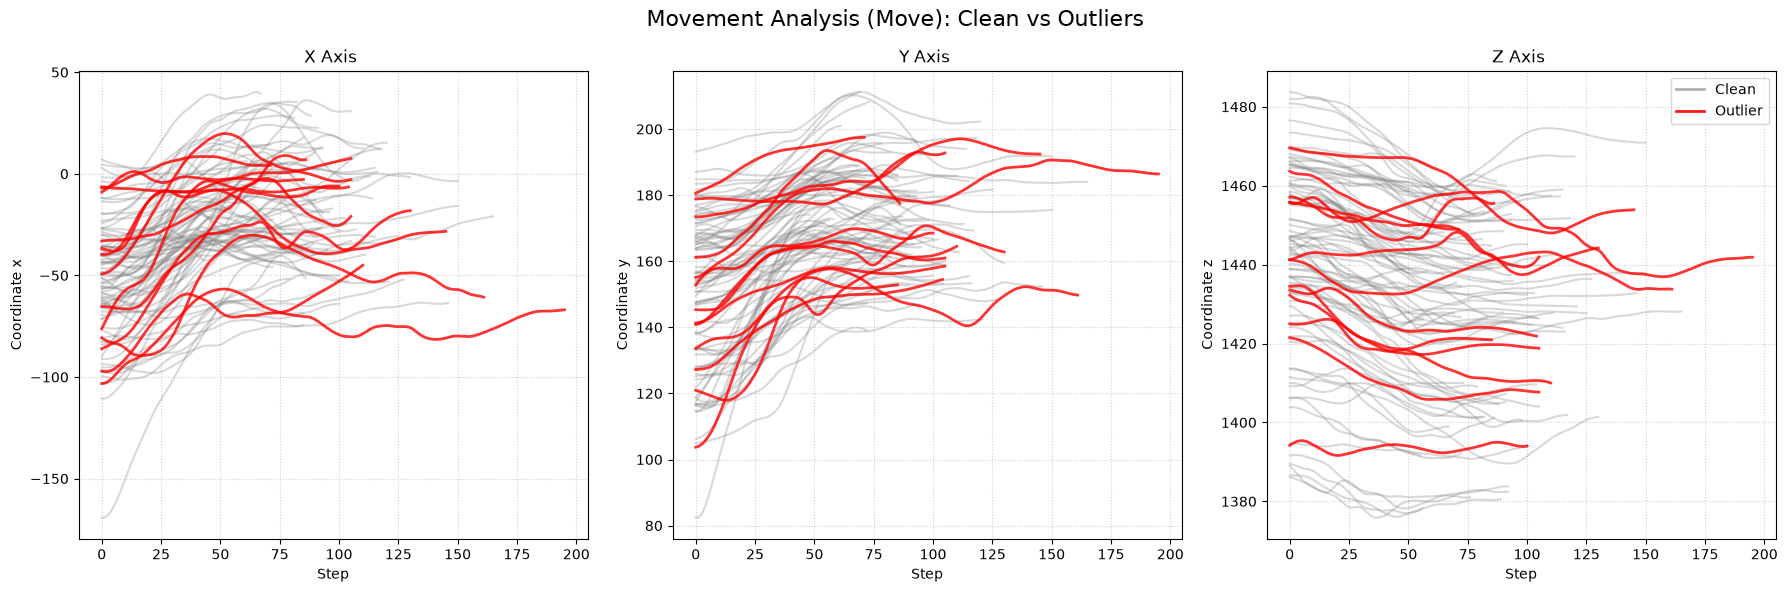

A desenhar trajetórias do Cotovelo...


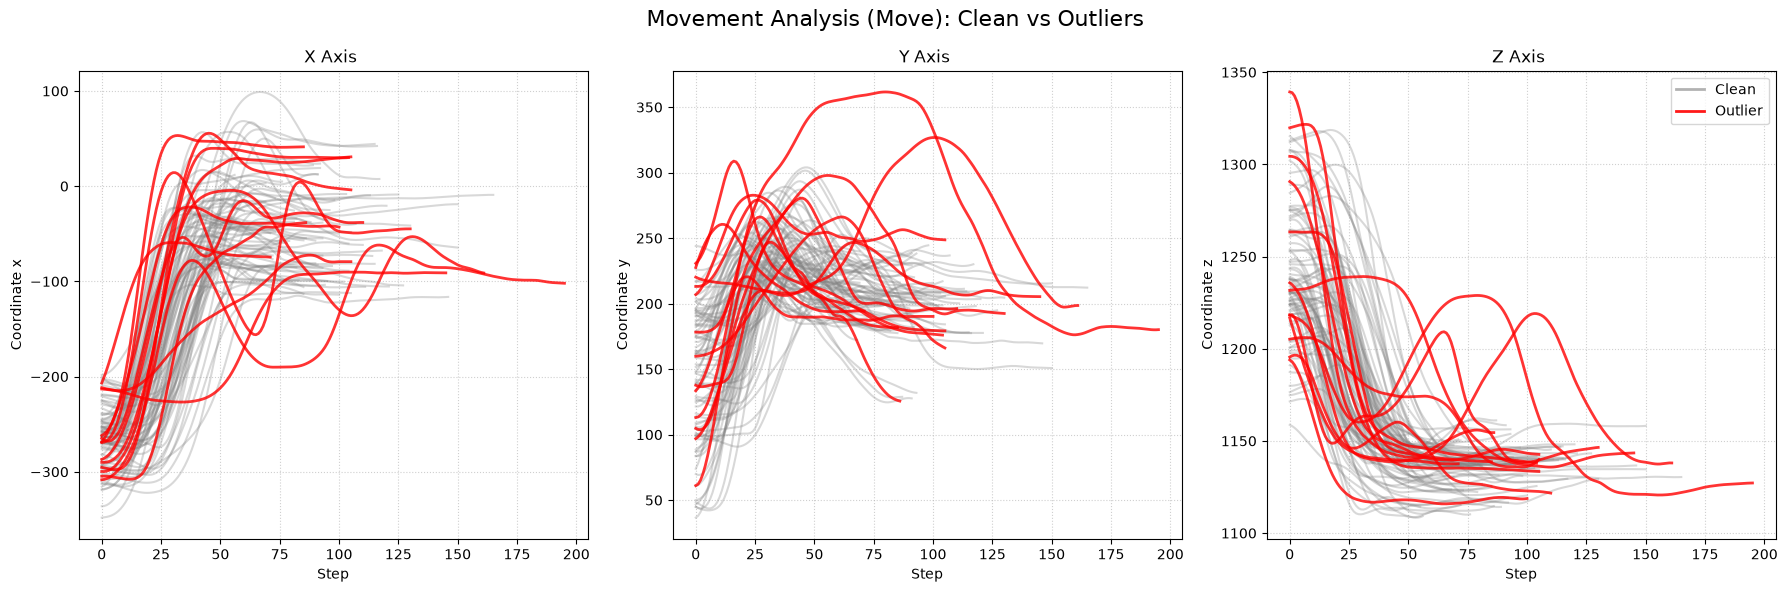

A desenhar trajetórias do Pulso...


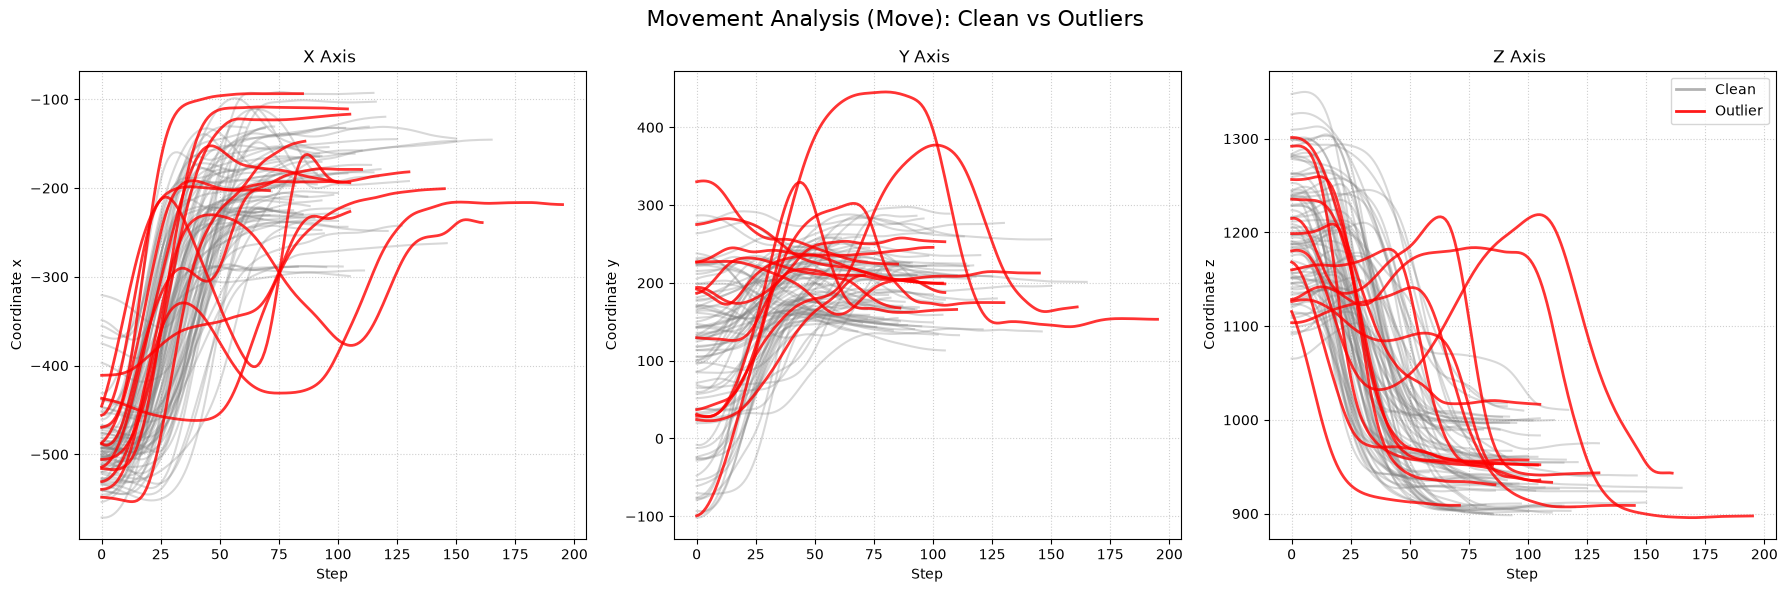

In [31]:
# 1. Ver as trajetórias do Ombro (Índices 0, 1, 2)
print("A desenhar trajetórias do Ombro...")
plot_movement_data(X_movement_clean[:, :, 0:3], X_movement_outliers[:, :, 0:3], TARGET_MOVEMENT)

# 2. Ver as trajetórias do Cotovelo (Índices 3, 4, 5)
print("A desenhar trajetórias do Cotovelo...")
plot_movement_data(X_movement_clean[:, :, 3:6], X_movement_outliers[:, :, 3:6], TARGET_MOVEMENT)

# 3. Ver as trajetórias do Pulso/Mão (Índices 6, 7, 8)
print("A desenhar trajetórias do Pulso...")
plot_movement_data(X_movement_clean[:, :, 6:9], X_movement_outliers[:, :, 6:9], TARGET_MOVEMENT)

### Correr o PCA e LOF para o modelo vencedor, para exportar as variáveis

In [32]:
pca_final = PCA(n_components=int(best_params['n_components']))
pca_scores_final = pca_final.fit_transform(X_flat)

model_final = LocalOutlierFactor(
    n_neighbors=int(best_params['n_neighbors']), 
    contamination=best_params['contamination'], 
    metric='minkowski'
)
best_labels = model_final.fit_predict(pca_scores_final)

# 2. ATUALIZAR a tabela de metadados com as Labels de Ouro
results_temp = results_temp_base.copy()
results_temp['label'] = best_labels

# 3. AGORA SIM: O real_outliers_info tem os culpados corretos para a Faca cortar!
real_outliers_info = results_temp[results_temp['label'] == -1].copy()

### Exportar Inliers

In [33]:
# ---------------------------------------------------------
# Limpar e isolar APENAS o movimento pretendido
# ---------------------------------------------------------

# 0. Filtrar o DataFrame bruto para ter APENAS o movimento alvo (ex: só 'Move')
df_target_only = df[df['movLabel'] == TARGET_MOVEMENT].copy()

# 1. Garantir que temos apenas as chaves identificadoras dos outliers detetados pelo PCA
# (Assume que 'real_outliers_info' foi gerado no bloco anterior do PCA)
outliers_keys = real_outliers_info[['sub', 'repID', 'movID']].copy()

# 2. Fazer um merge (Anti-Join) do dataframe FILTRADO com a lista de outliers do PCA
# O indicator=True cria uma coluna chamada '_merge' que nos diz de onde veio a linha
df_cleaned = pd.merge(df_target_only, outliers_keys, on=['sub', 'repID', 'movID'], how='left', indicator=True)

# 3. Manter APENAS as linhas que estão limpas ('left_only')
df_cleaned = df_cleaned[df_cleaned['_merge'] == 'left_only'].drop(columns=['_merge'])

# --- VERIFICAÇÃO DE INTEGRIDADE ---
print(f"--- RESUMO DA LIMPEZA VIA PCA ({TARGET_MOVEMENT}) ---")
print(f"Linhas do movimento {TARGET_MOVEMENT} antes da limpeza: {len(df_target_only)}")
print(f"Linhas removidas (pertencentes a outliers do PCA): {len(df_target_only) - len(df_cleaned)}")
print(f"Linhas do movimento {TARGET_MOVEMENT} limpas: {len(df_cleaned)}")

# Para confirmar os movimentos únicos que sobraram do TARGET_MOVEMENT
movimentos_restantes = df_cleaned[['sub', 'repID', 'movID']].drop_duplicates()
n_removidos_esperados = len(outliers_keys)
print(f"\nMovimentos '{TARGET_MOVEMENT}' que SOBRARAM: {len(movimentos_restantes)}")
print(f"Movimentos originais eram {total_trials}, removemos {n_removidos_esperados}, batem certo? {len(movimentos_restantes) == (total_trials - n_removidos_esperados)}")

save_path = Configs.cached_all_sensors_PCA_inliers('LOF', TARGET_MOVEMENT) 
joblib.dump(df_cleaned, save_path)

--- RESUMO DA LIMPEZA VIA PCA (Move) ---
Linhas do movimento Move antes da limpeza: 9095
Linhas removidas (pertencentes a outliers do PCA): 1515
Linhas do movimento Move limpas: 7580

Movimentos 'Move' que SOBRARAM: 82
Movimentos originais eram 95, removemos 13, batem certo? True


['/home/hugo-guimar-es/Documents/GitHub/python_zeromq/Outlier_Removal/ICater/ICater_Shoulder_Elbow_Hand/cache/metadata/all_sensors_dtw/inliers/all_sensors_PCA_inliers_LOF_Move.pkl']